# Big Data Integration with Alaska
Reproducible monitor-subset lab. Run cells in order. Local sections download real Alaska records and execute Pandas, Dask, SQLite via SQLAlchemy, entity resolution, and plots. Spark, MongoDB and Kafka are opt-in and report their execution status. Local Spark is not a multi-node experiment.

Install dependencies in a fresh Python 3.12 environment with `%pip install -r requirements.txt`, then restart the kernel. For Spark use Java 17 and `pip install pyspark==3.5.7`; its Kafka connector must match Spark and Scala. Internet access is needed for the first dataset download. Data and generated results remain under `lab_data/` and `lab_results/` beside this notebook.

In [1]:
from pathlib import Path
import os, json, re, tarfile, hashlib, time, platform, importlib.metadata
import itertools, statistics, unicodedata
import numpy as np
import pandas as pd
import dask.dataframe as dd
import sqlalchemy as sa
import requests
import matplotlib.pyplot as plt
import seaborn as sns
DATA=Path('lab_data'); RESULTS=Path('lab_results')
DATA.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
RUN_SPARK=False
RUN_MONGO=False
RUN_STREAM=False
status={'pandas':'pending','dask':'pending','sql':'pending','spark':'not run','mongo':'not run','kafka':'not run'}
versions={p:importlib.metadata.version(p) for p in ['pandas','dask','sqlalchemy','matplotlib','seaborn']}
print(platform.platform(), versions)

Windows-11-10.0.22631-SP0 {'pandas': '2.2.3', 'dask': '2025.2.0', 'sqlalchemy': '2.0.39', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


## 1 Ingest heterogeneous JSON and retain provenance
The official repository distributes monitor.tar.gz. Each specification is a JSON object under a website directory. Ground truth uses `website//filename_without_extension`. The loader reads regular JSON members directly from the archive and extracts only CSV labels after checking their destination paths. This avoids thousands of small file writes. The SHA256 digest identifies the downloaded archive; it is a provenance fingerprint, not an independently verified checksum.

In [2]:
url='https://raw.githubusercontent.com/merialdo/research.alaska/main/monitor.tar.gz'
archive=DATA/'monitor.tar.gz'
if not archive.exists():
    response=requests.get(url,timeout=120); response.raise_for_status()
    archive.write_bytes(response.content)
digest=hashlib.sha256(archive.read_bytes()).hexdigest()
root=DATA/'monitor'; root.mkdir(exist_ok=True)
records=[]; attrs=[]; bad=[]
with tarfile.open(archive) as tf:
    for member in tf:
        if not member.isfile(): continue
        member_path=Path(member.name)
        if member_path.suffix.lower() not in {'.json','.csv'}: continue
        if member_path.is_absolute() or '..' in member_path.parts: raise ValueError('Unsafe archive path')
        if member_path.suffix.lower()=='.csv':
            target=(root/member.name).resolve()
            if not target.is_relative_to(root.resolve()): raise ValueError('Unsafe archive path')
            target.parent.mkdir(parents=True,exist_ok=True)
            target.write_bytes(tf.extractfile(member).read())
            continue
        try:
            obj=json.loads(tf.extractfile(member).read().decode('utf-8'))
            if not isinstance(obj,dict): raise ValueError('Expected specification object')
            source=member_path.parent.name; spec_id=f'{source}//{member_path.stem}'
            records.append({'spec_id':spec_id,'source':source,'raw':obj})
            attrs.extend({'spec_id':spec_id,'source':source,'attribute':k,'value':str(v)} for k,v in obj.items())
        except (ValueError,UnicodeError) as exc: bad.append({'file':member.name,'error':str(exc)})
raw=pd.DataFrame(records); long=pd.DataFrame(attrs)
assert len(raw)>0 and raw.spec_id.is_unique
pd.DataFrame(bad).to_csv(RESULTS/'quarantine.csv',index=False)
print({'records':len(raw),'sources':raw.source.nunique(),'attribute_names':long.attribute.nunique(),'quarantined':len(bad),'sha256':digest})
print('CSV files:',[str(p) for p in root.rglob('*.csv')])

{'records': 16662, 'sources': 26, 'attribute_names': 1688, 'quarantined': 0, 'sha256': '9084b8998d5afa283865dfcf8e1f3cc4137f6befbe431903a4d83df4b3f7b45d'}
CSV files: ['lab_data\\monitor\\monitor\\monitor_ground_truths\\monitor_entity_resolution_gt.csv', 'lab_data\\monitor\\monitor\\monitor_ground_truths\\monitor_schema_matching_gt.csv']


## 2 Schema matching and cleaning
This manually specified baseline maps a small set of attribute aliases; it does not learn mappings from evaluation labels. Raw fields are preserved. Conflicting mapped values are counted and a deterministic first nonempty value is selected. Missing brand/model stays missing. Screen size is converted from explicit cm or inch values; unitless numbers are rejected. Titles are unstructured text and model extraction is a fallible fallback.

In [3]:
def norm(x):
    if x is None or (isinstance(x,float) and pd.isna(x)): return ''
    return re.sub(r'\s+',' ',unicodedata.normalize('NFKC',str(x)).casefold()).strip()
aliases={'brand':{'brand','manufacturer'},'model':{'model','model number','manufacturer part number'},
         'screen_inches':{'screen size','screen size diagonal','display size'}}
def inches(v):
    v=norm(v)
    m=re.search(r"(\d+(?:\.\d+)?)\s*(cm|inches|inch|in\b|[\"']+)",v)
    if not m: return np.nan
    x=float(m.group(1)); x=x/2.54 if m.group(2)=='cm' else x
    return x if 5<=x<=100 else np.nan
def canonical(row):
    obj={norm(k):v for k,v in row['raw'].items()}; out={k:row[k] for k in ['spec_id','source']}
    out['title']=str(obj.get('<page title>','')); conflicts=0
    for target,names in aliases.items():
        values=[norm(obj[k]) for k in sorted(names) if k in obj and norm(obj[k]) not in {'','n/a','unknown','-'}]
        conflicts+=int(len(set(values))>1)
        out[target]=values[0] if values else ''
    out['screen_inches']=inches(out['screen_inches'])
    if not out['model']:
        tokens=re.findall(r'\b[a-z0-9-]+\b',norm(out['title']))
        out['model']=next((t for t in tokens if re.search('[a-z]',t) and re.search('[0-9]',t)), '')
    out['brand']=re.sub(r'[^a-z0-9]','',out['brand'])
    out['model']=re.sub(r'[^a-z0-9]','',out['model'])
    out['conflicts']=conflicts
    return out
clean=pd.DataFrame(canonical(row) for row in records)
clean['entity_key']=np.where(clean.brand.ne('') & clean.model.ne(''),clean.brand+'|'+clean.model,None)
# Specification duplicates and entity duplicates are different concepts.
assert clean.spec_id.is_unique
clean.to_csv(DATA/'canonical.csv',index=False)
quality={'records':len(clean),'sources':clean.source.nunique(),
 'missing_brand':int(clean.brand.eq('').sum()),'missing_model':int(clean.model.eq('').sum()),
 'missing_screen':int(clean.screen_inches.isna().sum()),'conflicting_records':int(clean.conflicts.gt(0).sum())}
status['pandas']='completed'; print(quality)

{'records': 16662, 'sources': 26, 'missing_brand': 8944, 'missing_model': 813, 'missing_screen': 8671, 'conflicting_records': 152}


## 3 Equivalent Pandas and Dask benchmarks
Both engines read the same canonical CSV, select nonmissing screen values, and aggregate count and mean by source. Every trial materializes its result. One warm-up and three trials exclude JSON parsing and canonicalization; filesystem caching remains uncontrolled. These measurements concern this local workload only. Larger-than-memory ingestion should write partitioned Parquet incrementally instead of constructing all records in RAM.

In [4]:
def pandas_job():
    x=pd.read_csv(DATA/'canonical.csv')
    return x.dropna(subset=['screen_inches']).groupby('source').screen_inches.agg(['count','mean']).sort_index()
def dask_job():
    x=dd.read_csv(str(DATA/'canonical.csv'),blocksize='256KiB',dtype={'brand':'object','model':'object','entity_key':'object'})
    return x.dropna(subset=['screen_inches']).groupby('source').screen_inches.agg(['count','mean']).compute().sort_index()
timings=[]
for name,fn in [('Pandas',pandas_job),('Dask',dask_job)]:
    fn()
    for trial in range(3):
        t=time.perf_counter(); result=fn(); elapsed=time.perf_counter()-t
        timings.append({'engine':name,'trial':trial+1,'seconds':elapsed})
pd.testing.assert_frame_equal(pandas_job(),dask_job(),check_dtype=False,check_index_type=False,rtol=1e-9)
timings=pd.DataFrame(timings); timings.to_csv(RESULTS/'timings.csv',index=False)
status['dask']='completed'; print(timings.groupby('engine').seconds.agg(['median','min','max']))

          median       min       max
engine                              
Dask    0.599537  0.448156  0.718584
Pandas  0.112287  0.108139  0.123994


## 4 SQL and document integration
The local SQL exercise stages source-level metadata derived from Alaska in SQLite, retrieves it with SQLAlchemy, and joins it to the CSV. This is a controlled format integration exercise, not an independently collected dataset. MongoDB optionally round-trips the original documents through a dedicated lab collection. Enable it only against a disposable local lab database; inserts use idempotent upserts.

In [5]:
engine=sa.create_engine('sqlite:///'+str((DATA/'lab.sqlite').resolve()))
source_meta=clean.groupby('source').size().rename('source_record_count').reset_index()
source_meta.to_sql('sources',engine,if_exists='replace',index=False)
with engine.connect() as con: sql_meta=pd.read_sql(sa.text('SELECT source, source_record_count FROM sources'),con)
csv=pd.read_csv(DATA/'canonical.csv',keep_default_na=False)
unified=csv.merge(sql_meta,on='source',how='left',validate='many_to_one')
assert len(unified)==len(clean) and unified.source_record_count.notna().all()
status['sql']='completed'; print(unified[['spec_id','source_record_count']].head())
if RUN_MONGO:
    from pymongo import MongoClient, UpdateOne
    client=MongoClient(os.getenv('MONGO_URI','mongodb://localhost:27017'),serverSelectionTimeoutMS=5000)
    client.admin.command('ping'); coll=client.alaska_lab.specifications
    coll.bulk_write([UpdateOne({'_id':r['spec_id']},{'$set':{'source':r['source'],'raw':r['raw']}},upsert=True) for r in records])
    docs=pd.DataFrame(coll.find({'_id':{'$in':clean.spec_id.tolist()}},{'raw':1}))
    docs=docs.rename(columns={'_id':'spec_id','raw':'mongo_raw'})
    unified=unified.merge(docs,on='spec_id',how='left',validate='one_to_one')
    status['mongo']='completed'; client.close()
unified.to_json(RESULTS/'unified.jsonl',orient='records',lines=True)

                 spec_id  source_record_count
0  www.shopmania.com//56                  108
1  www.shopmania.com//61                  108
2  www.shopmania.com//80                  108
3  www.shopmania.com//62                  108
4  www.shopmania.com//34                  108


## 5 Entity resolution and labeled evaluation
Match only exact normalized brand and model within a block, across different websites. Empty keys never match. No fuzzy threshold is tuned on test labels. Evaluate on the labeled subset, treating labels as complete only within that subset. Ground truth is not joined into features. Unlabeled records are excluded from scoring; the score cannot establish accuracy across all Alaska records. Candidate recall is measured against all cross-source true pairs, so blocking misses count as false negatives.

In [6]:
truth_files=[]
for p in root.rglob('*.csv'):
    header=pd.read_csv(p,nrows=0).columns
    if {'entity_id','spec_id'}<=set(header): truth_files.append(p)
if not truth_files: raise FileNotFoundError('Entity ground truth CSV not found')
truth=pd.concat([pd.read_csv(p,dtype=str)[['entity_id','spec_id']] for p in truth_files]).drop_duplicates()
truth['spec_id']=truth.spec_id.str.replace('\\','/',regex=False).str.replace(r'\.json$','',regex=True)
memberships=truth.groupby('spec_id').entity_id.nunique()
ambiguous_ids=memberships[memberships>1].index
truth=truth[~truth.spec_id.isin(ambiguous_ids)]
print('Excluded multi-entity specification IDs:',len(ambiguous_ids))
labeled=clean.merge(truth,on='spec_id',validate='one_to_one')
assert len(labeled)>0, 'Check archive identifier layout'
def pairs(frame,key):
    out=set()
    for _,g in frame.dropna(subset=[key]).groupby(key):
        for a,b in itertools.combinations(g[['spec_id','source']].itertuples(index=False,name=None),2):
            if a[1]!=b[1]: out.add(tuple(sorted((a[0],b[0]))))
    return out
pred=pairs(labeled,'entity_key'); actual=pairs(labeled,'entity_id')
tp=len(pred & actual); fp=len(pred-actual); fn=len(actual-pred)
precision=tp/(tp+fp) if tp+fp else 0.; recall=tp/(tp+fn) if tp+fn else 0.
er={'excluded_multi_entity_ids':len(ambiguous_ids),'labeled_records':len(labeled),'true_pairs':len(actual),'predicted_pairs':len(pred),'tp':tp,'fp':fp,'fn':fn,
    'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}
print(er)
# Schema baseline coverage, with no evaluation-label-driven mapping.
schema_files=[p for p in root.rglob('*.csv') if {'source_attribute_id','target_attribute_name'}<=set(pd.read_csv(p,nrows=0).columns)]
schema_summary={}
if schema_files:
    sg=pd.concat([pd.read_csv(p,dtype=str) for p in schema_files]).drop_duplicates()
    alias_map={a:t for t,names in aliases.items() for a in names}
    sg['prediction']=sg.source_attribute_id.str.split('//').str[-1].map(norm).map(alias_map)
    # Target naming differs by mediated schema; report coverage only, not false accuracy.
    schema_summary={'labeled_attributes':len(sg),'mapped_attributes':int(sg.prediction.notna().sum())}
    print('Schema label coverage:',schema_summary)

Excluded multi-entity specification IDs: 9
{'excluded_multi_entity_ids': 9, 'labeled_records': 2264, 'true_pairs': 9148, 'predicted_pairs': 672, 'tp': 667, 'fp': 5, 'fn': 8481, 'precision': 0.9925595238095238, 'recall': 0.07291211193703542, 'f1': 0.1358452138492872}
Schema label coverage: {'labeled_attributes': 1344, 'mapped_attributes': 25}


## 6 Spark DataFrame and RDD transformations
Enable RUN_SPARK and install PySpark/Java first. Set SPARK_MASTER to a real cluster URL for distributed execution. These jobs use the same CSV and compute the same source counts and means; collect is safe only for the small aggregate. Spark startup and the first execution are reported separately from three warm trials. Local mode demonstrates APIs without establishing cluster performance.

In [7]:
if RUN_SPARK:
    from pyspark.sql import SparkSession, functions as F, types as T
    t=time.perf_counter()
    spark=SparkSession.builder.master(os.getenv('SPARK_MASTER','local[2]')).appName('AlaskaLab').getOrCreate()
    print('Spark startup seconds',time.perf_counter()-t)
    schema=T.StructType([T.StructField(c,T.DoubleType() if c=='screen_inches' else T.StringType(),True) for c in clean.columns])
    def spark_frame():
        s=spark.read.option('header',True).option('multiLine',True).schema(schema).csv(str((DATA/'canonical.csv').resolve()))
        return s.filter(F.col('screen_inches').isNotNull()).groupBy('source').agg(F.count('*').alias('count'),F.avg('screen_inches').alias('mean'))
    def spark_rdd():
        s=spark.read.option('header',True).option('multiLine',True).schema(schema).csv(str((DATA/'canonical.csv').resolve()))
        return (s.select('source','screen_inches').rdd.filter(lambda r:r[1] is not None)
          .map(lambda r:(r[0],(1,r[1]))).reduceByKey(lambda a,b:(a[0]+b[0],a[1]+b[1]))
          .mapValues(lambda v:(v[0],v[1]/v[0])).collect())
    reference=pandas_job()
    for name,fn in [('Spark DataFrame',lambda:spark_frame().toPandas().set_index('source').sort_index()),
                    ('Spark RDD',lambda:pd.DataFrame([(k,*v) for k,v in spark_rdd()],columns=['source','count','mean']).set_index('source').sort_index())]:
        t=time.perf_counter(); value=fn(); print(name,'first action seconds',time.perf_counter()-t)
        pd.testing.assert_frame_equal(reference,value,check_dtype=False,check_index_type=False,rtol=1e-8)
        for trial in range(3):
            t=time.perf_counter(); fn(); timings.loc[len(timings)]=[name,trial+1,time.perf_counter()-t]
    # Join source metadata and transform with native expressions.
    dimension=spark.createDataFrame(sql_meta)
    joined=spark.read.option('header',True).option('multiLine',True).schema(schema).csv(str((DATA/'canonical.csv').resolve())).join(F.broadcast(dimension),'source','left')
    print('Joined rows',joined.count()); status['spark']='completed'
else: print('Spark not run: enable RUN_SPARK after Java/PySpark setup')

Spark not run: enable RUN_SPARK after Java/PySpark setup


## 7 API ingestion through Kafka and Structured Streaming
Alaska is static. The optional producer polls an HTTP JSON event endpoint you provide; it is an additional source, not a live Alaska feed. Expected response: a JSON list of objects with event_id, spec_id, event_time (ISO8601 UTC), and numeric price. Supply API_URL and KAFKA_BOOTSTRAP. Run a Kafka broker and create topic alaska-events before enabling. Spark 3.5.7 needs org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.7 configured before the Spark session starts, for example through PYSPARK_SUBMIT_ARGS. Restart the kernel after changing connector settings.

The bounded polling loop sends only ten polls. Stable event IDs permit retry deduplication. The consumer drops invalid records, applies a ten-minute watermark, deduplicates within it, joins static specifications, and writes checkpointed Parquet. Events beyond the watermark can be dropped; idempotent upstream IDs and downstream merge logic are still needed for end-to-end guarantees. Stop the returned query explicitly when finished.

In [8]:
if RUN_STREAM:
    assert RUN_SPARK, 'Enable Spark first'
    from kafka import KafkaProducer
    from datetime import datetime, timezone
    bootstrap=os.environ['KAFKA_BOOTSTRAP']; endpoint=os.environ['API_URL']
    producer=KafkaProducer(bootstrap_servers=bootstrap,acks='all',retries=3,
        value_serializer=lambda v:json.dumps(v).encode(),key_serializer=lambda k:k.encode())
    try:
        for _ in range(10):
            response=requests.get(endpoint,timeout=15); response.raise_for_status(); events=response.json()
            if not isinstance(events,list): raise ValueError('API must return an event list')
            for event in events:
                if not {'event_id','spec_id','event_time','price'}<=event.keys(): raise ValueError('Missing event fields')
                producer.send('alaska-events',key=str(event['event_id']),value=event).get(timeout=15)
            time.sleep(1)
        producer.flush()
    finally: producer.close()
    event_schema='event_id STRING, spec_id STRING, event_time TIMESTAMP, price DOUBLE'
    stream=spark.readStream.format('kafka').option('kafka.bootstrap.servers',bootstrap).option('subscribe','alaska-events').option('startingOffsets','earliest').load()
    events=stream.select(F.from_json(F.col('value').cast('string'),event_schema).alias('e')).select('e.*')
    valid=events.filter('event_id IS NOT NULL AND spec_id IS NOT NULL AND event_time IS NOT NULL AND price >= 0')
    unique=valid.withWatermark('event_time','10 minutes').dropDuplicatesWithinWatermark(['event_id'])
    dim=spark.createDataFrame(clean[['spec_id','source']])
    query=(unique.join(dim,'spec_id','left').writeStream.format('parquet').outputMode('append')
       .option('path',str((RESULTS/'stream_events').resolve()))
       .option('checkpointLocation',str((RESULTS/'stream_checkpoint').resolve())).start())
    try:
        query.processAllAvailable(); print(query.lastProgress)
        status['kafka']='completed bounded API polling and stream drain'
    finally: query.stop()
else: print('API/Kafka streaming not run: external services and endpoint required')

API/Kafka streaming not run: external services and endpoint required


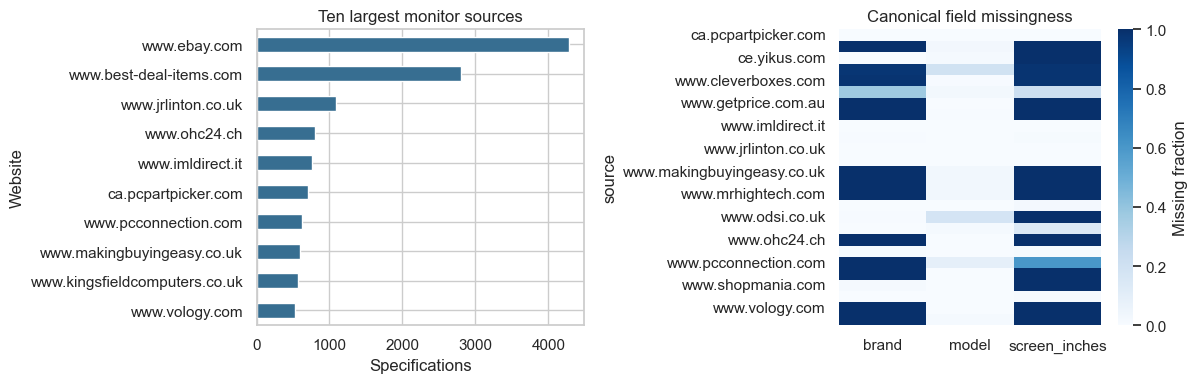

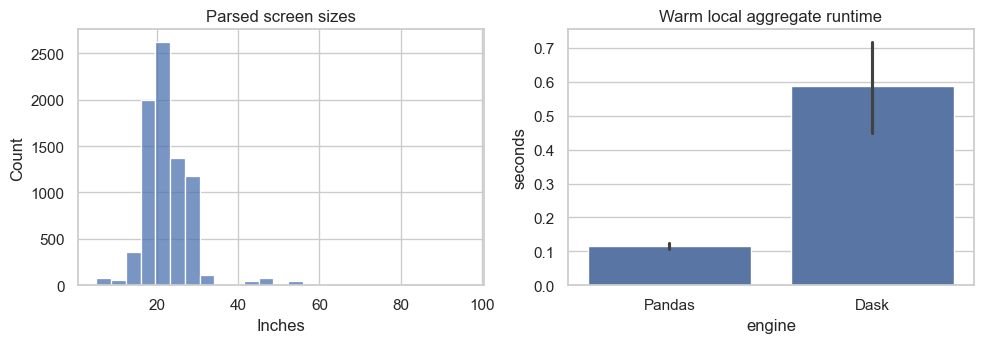

{
  "quality": {
    "records": 16662,
    "sources": 26,
    "missing_brand": 8944,
    "missing_model": 813,
    "missing_screen": 8671,
    "conflicting_records": 152
  },
  "entity_resolution": {
    "excluded_multi_entity_ids": 9,
    "labeled_records": 2264,
    "true_pairs": 9148,
    "predicted_pairs": 672,
    "tp": 667,
    "fp": 5,
    "fn": 8481,
    "precision": 0.9925595238095238,
    "recall": 0.07291211193703542,
    "f1": 0.1358452138492872
  },
  "schema_coverage": {
    "labeled_attributes": 1344,
    "mapped_attributes": 25
  },
  "status": {
    "pandas": "completed",
    "dask": "completed",
    "sql": "completed",
    "spark": "not run",
    "mongo": "not run",
    "kafka": "not run"
  },
  "versions": {
    "pandas": "2.2.3",
    "dask": "2025.2.0",
    "sqlalchemy": "2.0.39",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2"
  },
  "archive_sha256": "9084b8998d5afa283865dfcf8e1f3cc4137f6befbe431903a4d83df4b3f7b45d",
  "timing_medians": {
    "Dask": 0.5995370

In [9]:
# ## 8 Visual evaluation and saved evidence
# Source volume and missingness reveal integration coverage, not market share or sales. Screen-size plots exclude missing values and retain one row per listing, so popular entities may be represented repeatedly. Timing plots describe local execution only.

sns.set_theme(style='whitegrid')
fig,axes=plt.subplots(1,2,figsize=(12,4))
clean.source.value_counts().head(10).sort_values().plot.barh(ax=axes[0],color='#376e91')
axes[0].set(xlabel='Specifications',ylabel='Website',title='Ten largest monitor sources')
missing=pd.DataFrame({'brand':clean.brand.eq(''),'model':clean.model.eq(''),'screen_inches':clean.screen_inches.isna(),'source':clean.source}).groupby('source').mean()
sns.heatmap(missing,ax=axes[1],vmin=0,vmax=1,cmap='Blues',cbar_kws={'label':'Missing fraction'})
axes[1].set_title('Canonical field missingness'); fig.tight_layout(); fig.savefig(RESULTS/'quality.png',dpi=180); plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
sns.histplot(clean.screen_inches.dropna(),bins=25,ax=axes[0]); axes[0].set_title('Parsed screen sizes'); axes[0].set_xlabel('Inches')
sns.barplot(data=timings,x='engine',y='seconds',errorbar=('pi',100),ax=axes[1]); axes[1].set_title('Warm local aggregate runtime'); fig.tight_layout(); fig.savefig(RESULTS/'analysis.png',dpi=180); plt.show()
timings.to_csv(RESULTS/'timings.csv',index=False)
evidence={'quality':quality,'entity_resolution':er,'schema_coverage':schema_summary,'status':status,'versions':versions,'archive_sha256':digest,
 'timing_medians':timings.groupby('engine').seconds.median().to_dict()}
(RESULTS/'evidence.json').write_text(json.dumps(evidence,indent=2),encoding='utf-8')
print(json.dumps(evidence,indent=2))


## Interpretation and extensions
Inspect false positives by joining predicted pairs to titles before merging real entities. Missing or incorrect brand/model values restrict recall; screen size alone cannot establish identity. Do not impute identifiers with a common unknown value. Preserve source-level lineage and unresolved conflicts. For scalability, stream raw JSON into partitioned Parquet, benchmark at several genuine dataset sizes, record peak process/worker memory, and use identical distributed inputs. Replicated rows test system load but do not create new entity diversity. MongoDB, multi-node Spark, and Kafka performance remain unmeasured unless enabled and executed.

## References
1. Crescenzi et al. (2021). Alaska: A Flexible Benchmark for Data Integration Tasks. https://arxiv.org/abs/2101.11259
2. Official Alaska repository and format. https://github.com/merialdo/research.alaska
3. Dask DataFrame best practices. https://docs.dask.org/en/stable/dataframe-best-practices.html
4. Spark Kafka integration. https://spark.apache.org/docs/3.5.7/structured-streaming-kafka-integration.html
5. SQLAlchemy unified tutorial. https://docs.sqlalchemy.org/en/20/tutorial/